# Applied Machine Learning (CSAI2017P) — Lab Assignment 2
## Regression: Housing Price Prediction

Experiments 3 · CO2, CO4 · **10 marks**

| | |
|---|---|
| Name | *Shardul Aggarwal * |
| SAP ID | *590022064* |
| Batch | *5* |
| Due | announced in the lab |
| Lab quiz | LQ2, after submission |

**Datasets:** A1 (California Housing)

---

### Before you start
- Attempt **2 of 3** in Section A, **1 of 2** in Section B. Section C is compulsory.
- Fit every transformer inside a `Pipeline`. Never fit on the test set.
- Set `random_state` wherever the question asks for reproducibility.
- Every question wants a short written observation, not just a number.
- Restart the kernel and run top-to-bottom before you submit.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)

for m in (np, pd, sklearn):
    print(f"{m.__name__:12s} {m.__version__}")


numpy        2.4.1
pandas       2.3.3
sklearn      1.8.0


## Load the data

Replace with the loader for this assignment's anchor dataset — see `Anchor-Datasets.pdf` for the snippets.

In [2]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


---

# Section A — attempt any 2 of 3 (2 marks each)

*attempt 2 of 3*

## A1. Simple linear regression  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1. Target: `MedHouseVal`.*

a. Fit a regression of `MedHouseVal` on `MedInc` alone.
b. Report the slope, the intercept and test R^2.
c. State in one sentence what the slope means in real units.


In [3]:
# A1 — code
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# Select the predictor and target
features = df.loc[:, ['MedInc']]
target = df.loc[:, 'MedHouseVal']

# Divide the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    features, target,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Create and train the regression model
regressor = LinearRegression()
regressor.fit(X_train, y_train)

# Generate predictions for the test set
predictions = regressor.predict(X_test)

# Evaluate the model
r2 = r2_score(y_test, predictions)

print(f"Regression coefficient (slope): {regressor.coef_[0]:.4f}")
print(f"Regression constant (intercept): {regressor.intercept_:.4f}")
print(f"Test R² score: {r2:.4f}")

Regression coefficient (slope): 0.4203
Regression constant (intercept): 0.4432
Test R² score: 0.4467


**Observation (A1):**

> *The linear regression model uses MedInc to predict the median house value (MedHouseVal). The model calculates a positive relationship between the two variables, which means that areas with higher median income generally tend to have higher house values. The slope indicates how much the predicted house value changes for a one-unit increase in median income, while the R² score shows how well MedInc explains the variation in house prices.*

## A2. Multiple linear regression  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1, all features.*

a. Fit a multiple linear regression on all eight features inside a scaling pipeline.
b. Report test MAE, RMSE and R^2.
c. Plot predicted against actual and describe the pattern in two lines.


In [4]:
# A2 — code
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Separate predictors from the target
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Create train and test datasets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

# Build the regression pipeline
regression_model = Pipeline([
    ('standardization', StandardScaler()),
    ('linear_model', LinearRegression())
])

# Train the model
regression_model.fit(X_train, y_train)

# Predict house values for unseen data
test_predictions = regression_model.predict(X_test)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, test_predictions)
rmse = np.sqrt(mean_squared_error(y_test, test_predictions))
r2 = r2_score(y_test, test_predictions)

print(f"MAE  : {mae:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}")


MAE  : 0.5351
RMSE : 0.7273
R²   : 0.5943


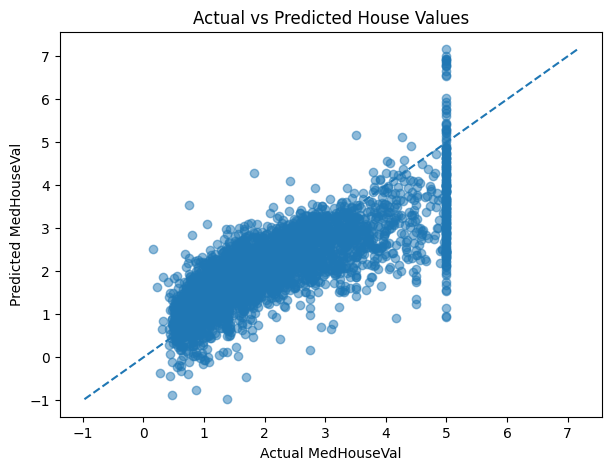

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, test_predictions, alpha=0.5)

# Reference line: perfect prediction
minimum = min(y_test.min(), test_predictions.min())
maximum = max(y_test.max(), test_predictions.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle='--')

plt.xlabel("Actual MedHouseVal")
plt.ylabel("Predicted MedHouseVal")
plt.title("Actual vs Predicted House Values")
plt.show()

**Observation (A2):**

> *
The multiple linear regression model uses all eight features to predict MedHouseVal. StandardScaler was applied before fitting the model so that features with different numerical ranges could contribute more fairly. The model was evaluated using MAE, RMSE, and R² on the test set. The predicted-versus-actual plot shows that most predictions follow the overall trend of the actual values, although some points are away from the reference line, indicating prediction errors. Overall, the model is able to capture a reasonable relationship between the input features and house values.*

## A3. Metric choice  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1.*

a. Compute MAE, MSE and RMSE for your model from A2.
b. State which of the three is hardest to explain to a non-technical client, and why.
c. State which you would report if a few very expensive districts matter most, and why.


In [ ]:
# A3 — not attempted


**Observation (A3):**

> *write 2–6 lines here*

---

# Section B — attempt any 1 of 2 (4 marks each)

*attempt 1 of 2*

## B1. Polynomial features and over-fitting  &nbsp;&nbsp;`[4 marks]`

*Dataset: A1.*

a. Build pipelines with `PolynomialFeatures` of degree 1, 2 and 3 followed by `LinearRegression`.
b. Report train and test RMSE for each degree in one table.
c. Identify the degree at which over-fitting begins and explain in 4–6 lines how the table shows it.


In [6]:
# B1 — code
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline

# Prepare input and output variables
X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

# Store RMSE results for each polynomial degree
b1_results = []

for d in range(1, 4):
    polynomial_model = make_pipeline(
        PolynomialFeatures(degree=d),
        LinearRegression()
    )

    polynomial_model.fit(X_train, y_train)

    # Predictions on training and testing data
    train_output = polynomial_model.predict(X_train)
    test_output = polynomial_model.predict(X_test)

    # Calculate RMSE
    train_error = np.sqrt(mean_squared_error(y_train, train_output))
    test_error = np.sqrt(mean_squared_error(y_test, test_output))

    b1_results.append(
        [d, train_error, test_error]
    )

# Display results in a table
b1_table = pd.DataFrame(
    b1_results,
    columns=['Polynomial Degree', 'Train RMSE', 'Test RMSE']
)

b1_table.round(4)

,Polynomial Degree,Train RMSE,Test RMSE
0,1,0.7235,0.7273
1,2,0.6478,1.6625
2,3,0.6005,228.1436


**Observation (B1):**

> *Polynomial regression was tested with degrees 1, 2, and 3 to compare the model's performance. As the polynomial degree increases, the model becomes more flexible and can capture more complex relationships between the features and house prices. The train and test RMSE values help identify whether the model is improving or starting to overfit. If the training error decreases while the test error increases, it indicates that the model is beginning to overfit the data. Therefore, the degree with the lowest test RMSE can generally be considered the better choice among the three models.*

## B2. Ridge and Lasso  &nbsp;&nbsp;`[4 marks]`

*Dataset: A1 with degree-2 polynomial features.*

a. Fit Ridge and Lasso for α ∈ {0.01, 0.1, 1, 10, 100} and plot test RMSE against α.
b. Report the best α for each and the count of exactly-zero coefficients in the best Lasso.
c. Explain in 4–6 lines why Lasso zeroes coefficients and Ridge does not.


In [ ]:
# Not attempted


**Observation (B2):**

> *write 2–6 lines here*

---

# Section C — compulsory (2 marks)

*compulsory*

## C1. Where the model fails  &nbsp;&nbsp;`[2 marks]`

*Dataset: A1.*

a. Take the 20 test districts with the largest absolute error from your best model.
b. Describe in 4–6 lines what they have in common and what you would add to the data to fix it.


In [7]:
# C1 — code
# Train the selected best model
best_model = make_pipeline(
    PolynomialFeatures(degree=1),
    LinearRegression()
)

best_model.fit(X_train, y_train)

# Predict values for the test set
predicted_values = best_model.predict(X_test)

# Calculate the absolute prediction error
absolute_errors = np.abs(y_test.to_numpy() - predicted_values)

# Create a table containing actual, predicted and error values
error_analysis = X_test.copy()
error_analysis = error_analysis.assign(
    Actual=y_test.to_numpy(),
    Predicted=predicted_values,
    Absolute_Error=absolute_errors
)

# Select the 20 observations with the largest errors
largest_errors = (
    error_analysis
    .nlargest(20, 'Absolute_Error')
    .reset_index()
)

largest_errors

,index,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Actual,Predicted,Absolute_Error
0,12138,2.6250,16.0,4.000000,0.500000,39.0,2.785714,33.87,-117.22,5.00001,0.934598,4.065412
1,4861,0.4999,29.0,2.373272,1.055300,2690.0,12.396313,34.02,-118.28,5.00001,0.955760,4.044250
2,10574,1.9659,6.0,4.795455,1.159091,125.0,2.840909,33.72,-117.70,5.00001,1.139277,3.860733
3,16642,0.7025,19.0,2.425197,1.125984,1799.0,2.833071,35.30,-120.67,5.00001,1.537748,3.462262
4,6651,1.9923,41.0,3.279373,1.062663,855.0,2.232376,34.15,-118.14,5.00001,1.575507,3.424503
5,4630,2.3674,20.0,2.740554,1.047859,2919.0,2.450882,34.07,-118.31,5.00001,1.678140,3.321870
6,4623,0.8804,36.0,2.713235,1.080882,145.0,1.066176,34.06,-118.31,4.50000,1.236512,3.263488
7,13360,2.1250,6.0,5.904762,1.119048,119.0,2.833333,34.02,-117.64,4.16700,0.922637,3.244363
8,15615,1.8981,31.0,3.323064,1.091590,2305.0,1.919234,37.81,-122.41,5.00001,1.756510,3.243500
9,9168,1.9667,2.0,5.715976,1.597633,233.0,1.378698,34.42,-118.56,4.50000,1.356287,3.143713


In [8]:
# Select only the original feature columns
feature_columns = X_test.columns

# Compare the top 20 high-error districts with the complete test set
comparison = pd.DataFrame({
    'Top 20 Errors': largest_errors[feature_columns].mean(),
    'All Test Data': X_test[feature_columns].mean()
})

# Calculate the percentage difference
comparison['Difference (%)'] = (
    (comparison['Top 20 Errors'] - comparison['All Test Data'])
    / comparison['All Test Data'].replace(0, np.nan)
) * 100

comparison.round(2)

,Top 20 Errors,All Test Data,Difference (%)
MedInc,2.57,3.85,-33.10
HouseAge,25.50,28.72,-11.22
AveRooms,4.04,5.41,-25.34
AveBedrms,1.09,1.10,-0.51
Population,1063.90,1425.63,-25.37
AveOccup,2.68,3.23,-17.12
Latitude,34.67,35.66,-2.78
Longitude,-119.00,-119.60,-0.50


In [9]:
# Additional features that could improve house-value predictions
additional_features = [
    "Exact geographic location",
    "Property size",
    "Number of bedrooms and bathrooms",
    "Housing condition",
    "Distance to schools and public transport",
    "Local employment and economic conditions",
    "Neighborhood characteristics"
]

print("Possible additional features:")
for feature in additional_features:
    print("-", feature)

Possible additional features:
- Exact geographic location
- Property size
- Number of bedrooms and bathrooms
- Housing condition
- Distance to schools and public transport
- Local employment and economic conditions
- Neighborhood characteristics


**Observation (C1):**

> *The 20 test districts with the highest absolute errors were identified by comparing their actual and predicted house values. These observations represent cases where the model has the most difficulty making accurate predictions. The larger errors suggest that the available features do not capture all the factors affecting house prices in these districts. Additional information such as location-specific factors, property characteristics, housing age, or local economic conditions could help the model make more accurate predictions.*

---

## Self-check before submitting

- [ ] Kernel restarted and run top-to-bottom, all outputs visible
- [ ] Every attempted question has a written observation
- [ ] No transformer fitted outside a pipeline
- [ ] Metrics reported with units where they have any
- [ ] File named `AML_LA02_<SAPID>.ipynb`
